In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from scipy.stats import wilcoxon

## Dataset

We will use a synthetic dataset containing measurements from 10 subjects before and after a treatment.

Each subject has two measurements, so the observations are paired.

Our objective is to determine whether the treatment is associated with a statistically significant change in the measurements.

In [6]:
df = pd.DataFrame({
    "subject": range(1, 11),
    "before": [20, 25, 30, 35, 40, 45, 50, 55, 60, 65],
    "after":  [18, 24, 31, 37, 43, 49, 55, 61, 67, 73]
})

df

,subject,before,after
0,1,20,18
1,2,25,24
2,3,30,31
3,4,35,37
4,5,40,43
5,6,45,49
6,7,50,55
7,8,55,61
8,9,60,67
9,10,65,73


## Calculate Paired Differences

In [7]:
df["difference"] = df["after"] - df["before"]

df

,subject,before,after,difference
0,1,20,18,-2
1,2,25,24,-1
2,3,30,31,1
3,4,35,37,2
4,5,40,43,3
5,6,45,49,4
6,7,50,55,5
7,8,55,61,6
8,9,60,67,7
9,10,65,73,8


In [8]:
print("Number of subjects:", len(df))
print("Before median:", df["before"].median())
print("After median:", df["after"].median())
print("Median difference:", df["difference"].median())

print("Positive differences:", (df["difference"] > 0).sum())
print("Negative differences:", (df["difference"] < 0).sum())
print("Zero differences:", (df["difference"] == 0).sum())

Number of subjects: 10
Before median: 42.5
After median: 46.0
Median difference: 3.5
Positive differences: 8
Negative differences: 2
Zero differences: 0


## Visualizing the Differences

Before running the test, we can visualize the paired differences using a histogram and a box plot.

These plots help us understand the distribution, identify unusual observations, and assess whether the symmetry assumption seems reasonable.

The Wilcoxon Signed-Rank Test does not require the differences to follow a normal distribution. However, approximate symmetry of the population differences is important when interpreting the test specifically as a test of location or median shift.

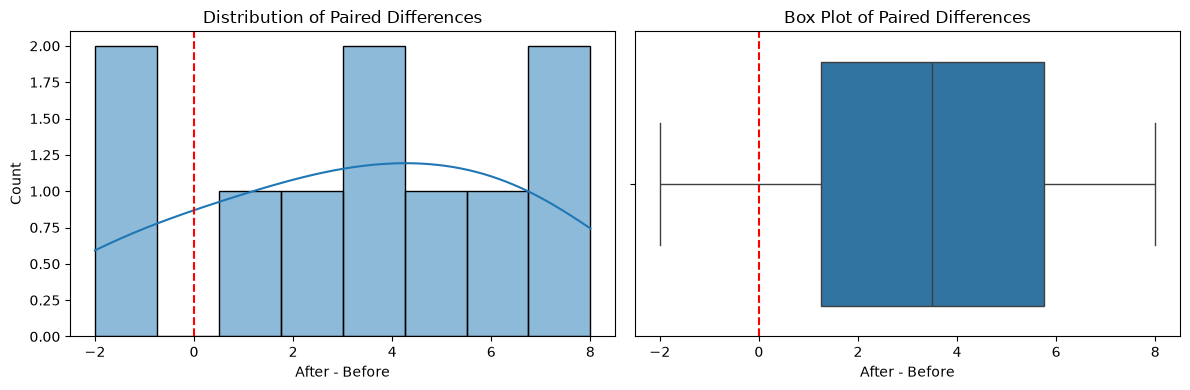

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

sns.histplot(df["difference"], bins=8, kde=True, ax=axes[0])
axes[0].axvline(0, color="red", linestyle="--")
axes[0].set_title("Distribution of Paired Differences")
axes[0].set_xlabel("After - Before")

sns.boxplot(x=df["difference"], ax=axes[1])
axes[1].axvline(0, color="red", linestyle="--")
axes[1].set_title("Box Plot of Paired Differences")
axes[1].set_xlabel("After - Before")

plt.tight_layout()
plt.show()

## Hypothesis Formulation

We will use a two-sided Wilcoxon Signed-Rank Test because we want to determine whether a change exists in either direction.

**Null Hypothesis (H₀):** There is no systematic location shift between the before and after measurements.

**Alternative Hypothesis (H₁):** There is a systematic location shift between the before and after measurements.

Under the symmetry assumption, these hypotheses can be interpreted in terms of the population median of the paired differences:

- H₀: The population median difference is zero.
- H₁: The population median difference is not zero.

We will use a significance level of 0.05.

$$
\alpha = 0.05
$$

In [10]:
df["abs_difference"] = df["difference"].abs()

df["rank"] = df["abs_difference"].rank(
    method="average"
)

df

,subject,before,after,difference,abs_difference,rank
0,1,20,18,-2,2,3.5
1,2,25,24,-1,1,1.5
2,3,30,31,1,1,1.5
3,4,35,37,2,2,3.5
4,5,40,43,3,3,5.0
5,6,45,49,4,4,6.0
6,7,50,55,5,5,7.0
7,8,55,61,6,6,8.0
8,9,60,67,7,7,9.0
9,10,65,73,8,8,10.0


In [11]:
positive_rank_sum = df.loc[
    df["difference"] > 0, "rank"
].sum()

negative_rank_sum = df.loc[
    df["difference"] < 0, "rank"
].sum()

print("Positive rank sum:", positive_rank_sum)
print("Negative rank sum:", negative_rank_sum)

Positive rank sum: 50.0
Negative rank sum: 5.0


##  Performing the Wilcoxon Signed-Rank Test

We will use SciPy's `wilcoxon()` function to compare the paired measurements.

The test will be two-sided, so it can detect either an increase or a decrease.

Because this example contains tied absolute differences, we will use the normal approximation with continuity correction rather than treating the standard exact distribution as if there were no ties.

In [12]:
stat, p_value = wilcoxon(
    df["before"],
    df["after"],
    alternative="two-sided",
    method="approx",
    correction=True
)

print("Wilcoxon Statistic:", stat)
print("P-value:", p_value)

Wilcoxon Statistic: 5.0
P-value: 0.024744672046398936


##  Statistical Decision

Compare the p-value with the significance level of 0.05.

- If p-value < 0.05, reject the null hypothesis.
- If p-value ≥ 0.05, fail to reject the null hypothesis.

The p-value represents the probability, assuming the null hypothesis and the test's assumptions, of obtaining a result at least as extreme as the observed result. It is not the probability that the null hypothesis is true.

In [13]:
alpha = 0.05

if p_value < alpha:
    print("Reject H0")
    print("The result is statistically significant.")
else:
    print("Fail to reject H0")
    print("There is insufficient evidence of a statistically significant difference.")

Reject H0
The result is statistically significant.


In [14]:
effect_size = (
    positive_rank_sum - negative_rank_sum
) / (
    positive_rank_sum + negative_rank_sum
)

print("Matched-pairs rank-biserial correlation:", effect_size)

Matched-pairs rank-biserial correlation: 0.8181818181818182


## 11. Final Conclusion

The Wilcoxon Signed-Rank Test was applied to paired before-and-after measurements from 10 synthetic subjects.

The test returned a statistic of 5.0 and a p-value of approximately 0.025. At the 5% significance level, the null hypothesis was rejected.

The matched-pairs rank-biserial correlation was approximately +0.818, indicating that positive differences dominated the ranks in this sample.

However, the paired differences were not approximately symmetric. Therefore, the result should not be interpreted as conclusive evidence of a population median shift. The example demonstrates how to calculate and report the test, while also showing why assumptions matter when interpreting its results.